<a href="https://colab.research.google.com/github/ibrhmgldmr3/fly_kingo/blob/main/notebooks/colab_brain.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# fly_kingo: sinek beyni hesapları (Colab, ücretsiz GPU)

Yerel makineyi yoran işleri burada çalıştırır: testler, karar yüzeyi, yüzey kontrolü, GRN ablasyonu.

**Başlamadan önce:** `Çalışma zamanı → Çalışma zamanı türünü değiştir → T4 GPU`.

Sonuçlar her batch'ten sonra Google Drive'a (`MyDrive/fly_kingo/`) yazılır. Colab bağlantısı koparsa
notebook'u baştan çalıştırmak yeterli; karar yüzeyi kaldığı yerden devam eder.

## 1. Ortam ve Drive

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
import sys; print(sys.version)

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
DRIVE = Path("/content/drive/MyDrive/fly_kingo")
(DRIVE / "flywire").mkdir(parents=True, exist_ok=True)
(DRIVE / "figures").mkdir(exist_ok=True)
print("Drive klasörü:", DRIVE)

name, memory.total [MiB]
Tesla T4, 15360 MiB
3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Mounted at /content/drive
Drive klasörü: /content/drive/MyDrive/fly_kingo


## 2. Kod

İki yol var:
- **GitHub:** `BRANCH` dalı klonlanır (yerel değişiklikler push edilmiş olmalı).
- **Zip:** `BRANCH = None` bırakın; yerelde üretilen `fly_kingo_colab.zip` dosyasını yükleyin
  (veya Drive'da `MyDrive/fly_kingo/fly_kingo_colab.zip` olarak bırakın).

In [2]:
BRANCH = "main"  # None ise zip kullanılır
REPO = "https://github.com/ibrhmgldmr3/fly_kingo.git"

import shutil, zipfile, os
ROOT = Path("/content/fly_kingo")
if ROOT.exists():
    shutil.rmtree(ROOT)

if BRANCH:
    !git clone --depth 1 --branch {BRANCH} {REPO} {ROOT}
else:
    bundle = DRIVE / "fly_kingo_colab.zip"
    if not bundle.exists():
        from google.colab import files
        uploaded = files.upload()  # fly_kingo_colab.zip seçin
        bundle = Path(next(iter(uploaded)))
    with zipfile.ZipFile(bundle) as z:
        z.extractall(ROOT)

os.chdir(ROOT)
!ls

Cloning into '/content/fly_kingo'...
remote: Enumerating objects: 59, done.
remote: Counting objects: 100% (59/59), done.
remote: Compressing objects: 100% (55/55), done.
remote: Total 59 (delta 0), reused 44 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (59/59), 348.70 KiB | 7.26 MiB/s, done.
alembic.ini	    docs	     migrations      README.md	tests
data		    environment.yml  notebooks	     scripts
docker-compose.yml  LICENSE	     pyproject.toml  src


## 3. Kurulum

In [3]:
# Colab'da CUDA'lı torch zaten kurulu; pip onu değiştirmez.
# pyproject Python 3.12 istiyor; Colab'ın sürümü farklıysa bile kurulumu dene.
!pip install -q --ignore-requires-python -e ".[brain,dev]"
import torch; print("torch", torch.__version__, "cuda:", torch.cuda.is_available())

  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.0/41.0 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 16.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 72.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 226.3/226.3 kB 27.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 215.5/215.5 kB 25.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 108.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.4/80.4 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 72.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.5/99.5 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 70.5 MB/s eta 0:00:00
  

## 4. Connectome verisi (Drive'da önbelleklenir, checksum doğrulanır)

In [4]:
data = ROOT / "data"
data.mkdir(exist_ok=True)
link = data / "flywire"
if not link.exists():
    link.symlink_to(DRIVE / "flywire")
!flyhire data download
!flyhire info

- Completeness_783.csv (Modeldeki tüm nöronlar (Shiu, v783))
  data/flywire/Completeness_783.csv  sha256=bbb847a4cc2caaa7a16349722d220c087317b946d148d4d592d94d250617a311
- Connectivity_783.parquet (İşaretli sinaptik bağlantılar (Shiu, v783))
  data/flywire/Connectivity_783.parquet  sha256=efeb23fb99098e9c390f6869969b2a121a2ee92c833cfc45ecb2c1d8e1af0347
- neuron_annotations.tsv (Nöron tipleri ve etiketleri (Schlegel et al. 2024, v783))
  data/flywire/neuron_annotations.tsv  sha256=b214970b55d2fbe0853bba536fdcb9e28730f4eb7ab06f600491df795da683cd
flyhire 0.1.0
Veri klasörü : /content/drive/MyDrive/fly_kingo/flywire
Eksik veri   : yok
LLM modeli   : anthropic/claude-sonnet-5-5


## 5. Testler

In [5]:
!pytest -q

........................                                                 [100%]
24 passed, 5 deselected in 46.76s


Yavaş (tam beyin) testleri CPU'da çalışır; Colab'ın 2 çekirdeğinde birkaç dakika sürebilir.

In [6]:
!pytest -q -m slow

.....                                                                    [100%]
5 passed, 24 deselected in 261.31s (0:04:21)


## 6. Karar yüzeyi (GPU)

Çıktı doğrudan Drive'a yazılır ve her batch'ten sonra kaydedilir. Yerelde yarım kalan
`data/surface_v783.npz` dosyanız varsa Drive'a `MyDrive/fly_kingo/surface_v783.npz` olarak koyun;
hesap oradan devam eder (dosya aynı beyin sürümüyle başlatılmış olmalı).

In [7]:
SURFACE = DRIVE / "surface_v783.npz"
!flyhire brain surface --device cuda --batch-conditions 24 --out {SURFACE}

288/726 nokta  (0.8 dk)
312/726 nokta  (1.6 dk)
336/726 nokta  (2.3 dk)
360/726 nokta  (3.1 dk)
384/726 nokta  (3.8 dk)
408/726 nokta  (4.6 dk)
432/726 nokta  (5.3 dk)
456/726 nokta  (6.1 dk)
480/726 nokta  (6.9 dk)
504/726 nokta  (7.6 dk)
528/726 nokta  (8.4 dk)
552/726 nokta  (9.1 dk)
576/726 nokta  (9.9 dk)
600/726 nokta  (10.7 dk)
624/726 nokta  (11.4 dk)
648/726 nokta  (12.2 dk)
672/726 nokta  (12.9 dk)
696/726 nokta  (13.7 dk)
720/726 nokta  (14.5 dk)
726/726 nokta  (14.8 dk)
Tamamlandı: /content/drive/MyDrive/fly_kingo/surface_v783.npz  (tam: True)


### Yüzey kontrolü ve görseller

 şeker     su    acı |  yüzey    sim     ±
  45.5   63.4  159.5 |    0.1    0.0   0.0
 135.3   78.2   66.6 |   67.9   67.8   4.3
 119.7   37.3  134.6 |    9.1    7.2   2.0
 188.4   49.6  189.8 |   16.3   13.6   3.5
 133.4   19.2   88.4 |   34.7   30.2   6.5
 177.3  139.5   65.3 |   83.1   85.2   2.8
 146.8   44.0   16.3 |   80.1   79.6   2.7
  32.0   68.0   93.0 |    1.1    0.2   0.4
  53.3  163.2   38.7 |   58.4   54.6   3.8
  25.9   18.3  119.7 |    0.0    0.0   0.0
 170.9  120.3  186.4 |   23.1   21.8   3.1
 145.0  172.1  185.9 |   16.8   15.4   3.3
 109.2  187.5   99.0 |   48.1   47.2   4.5
  54.8   90.4  133.0 |    2.4    0.6   0.8
  66.2  180.7   51.4 |   61.0   63.8   3.7
  68.0   51.8   71.1 |   15.6    9.8   3.1
   1.0  125.7   56.5 |    1.7    0.8   0.7
  13.6  123.4   35.3 |    8.6    6.0   3.0
  60.9   88.2   30.0 |   54.7   54.4   8.3
  43.6   94.9   95.3 |    5.1    5.2   2.5
  51.0   59.5   55.8 |   18.4   16.0   3.3
  52.1   96.6   42.4 |   43.8   46.4   5.6
  99.1   49

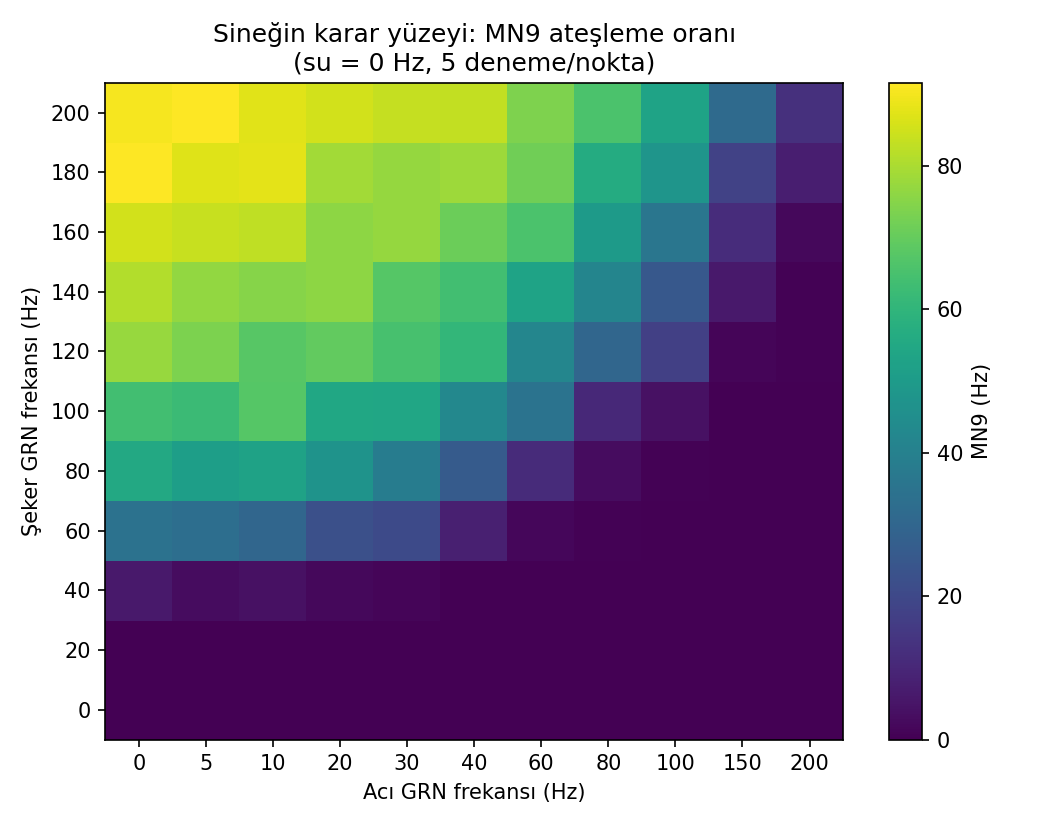

In [8]:
!flyhire brain check-surface --device cuda --points 24 --surface {SURFACE}
!flyhire brain heatmap --surface {SURFACE} --out {DRIVE}/figures/decision_surface.png
!flyhire brain heatmap --surface {SURFACE} --water 120 --out {DRIVE}/figures/decision_surface_water120.png

from IPython.display import Image, display
display(Image(str(DRIVE / "figures/decision_surface.png")))

## 7. (İsteğe bağlı) GRN ablasyonu

In [11]:
!python scripts/grn_ablation.py --device cuda --out {DRIVE}/grn_ablation.json

cihaz=cuda  süre=163 s
| Kanal | Çıkarılan nöron | Nokta | 20 nöron (Hz) | 19 nöron (Hz) | Fark ± SE (Hz) |
|---|---|---|---|---|---|
| sugar | `720575940612670570` | şeker 60 | 36.1 ± 8.5 | 35.6 ± 5.7 | -0.5 ± 3.2 |
| sugar | `720575940612670570` | şeker 100 | 68.7 ± 4.0 | 67.3 ± 5.6 | -1.4 ± 2.2 |
| sugar | `720575940612670570` | şeker 200 | 91.1 ± 4.6 | 95.9 ± 3.5 | +4.8 ± 1.8 |
| sugar | `720575940612670570` | şeker 100 + acı 30 | 52.6 ± 5.3 | 50.7 ± 3.8 | -1.9 ± 2.0 |
| sugar | `720575940612670570` | şeker 60 + su 80 | 62.5 ± 6.5 | 61.9 ± 4.6 | -0.6 ± 2.5 |
| sugar | `720575940640649691` | şeker 60 | 36.1 ± 8.5 | 34.6 ± 8.0 | -1.5 ± 3.7 |
| sugar | `720575940640649691` | şeker 100 | 68.7 ± 4.0 | 68.5 ± 2.3 | -0.2 ± 1.5 |
| sugar | `720575940640649691` | şeker 200 | 91.1 ± 4.6 | 88.9 ± 4.6 | -2.2 ± 2.0 |
| sugar | `720575940640649691` | şeker 100 + acı 30 | 52.6 ± 5.3 | 49.6 ± 7.4 | -3.0 ± 2.9 |
| sugar | `720575940640649691` | şeker 60 + su 80 | 62.5 ± 6.5 | 63.8 ± 5.2 | +1.3 ± 2.

## 8. Sonuçları yerele almak

Dosyalar Drive'da `MyDrive/fly_kingo/` altında. Yerelde `data/` ve `docs/figures/` içine kopyalayın.
İsterseniz buradan doğrudan indirin:

In [13]:
from google.colab import files
files.download(str(SURFACE))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>